In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv


# Bagging Ensemble Learning

## Objective

To understand and implement different Bagging techniques
using Machine Learning algorithms.

We will explore:

- Bagging
- Pasting
- Random Subspaces
- Random Patches
- Bagging with different base estimators

We will also implement Bagging Regressor using a
synthetically generated regression dataset.

The objective is to understand how combining multiple
models can improve prediction performance and reduce variance.

In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Classification algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Ensemble algorithms
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import BaggingRegressor

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv(
    '/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv'
)

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
print("Dataset Shape:", df.shape)
df.info()
df.describe()
df.isnull().sum()

Dataset Shape: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  p

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [5]:
df.drop(
    columns=['id', 'Unnamed: 32'],
    inplace=True,
    errors='ignore'
)

print("Updated Dataset Shape:", df.shape)

df.head()

Updated Dataset Shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


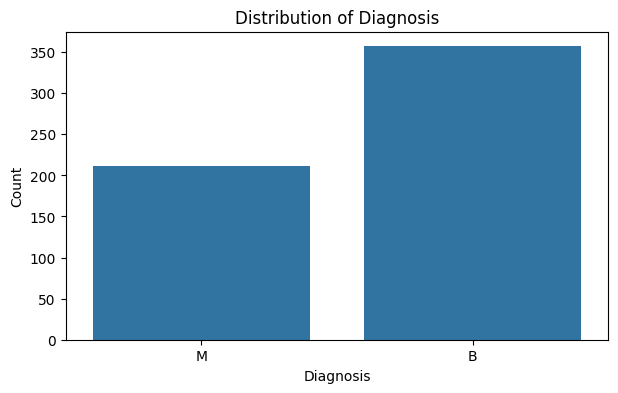

In [6]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x='diagnosis'
)

plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Count")

plt.show()

In [7]:
X = df.drop('diagnosis', axis=1)

y = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)


In [10]:
# Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Benign', 'Malignant']
))

Decision Tree Accuracy: 0.9298245614035088

Classification Report:
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



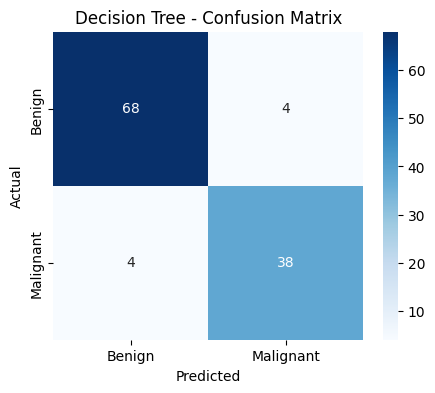

In [11]:
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

## 10. Bagging Classifier

Bagging stands for Bootstrap Aggregating.

It is an ensemble learning technique that trains multiple models independently using different bootstrap samples of the original training dataset.

### How Bagging works:

1. Randomly create multiple datasets from the original training data.
2. Sampling is performed with replacement.
3. Train a separate Decision Tree on each bootstrap dataset.
4. Each tree makes its own prediction.
5. Combine predictions using majority voting for classification.

The final prediction is based on the majority vote of all individual models.

### Important Parameters

- estimator: Base model used by the ensemble.
- n_estimators: Number of models to train.
- max_samples: Number or fraction of training samples used by each model.
- bootstrap: Whether sampling is performed with replacement.
- random_state: Ensures reproducibility.
- n_jobs: Number of CPU cores used for training.

In [12]:
# Create Bagging Classifier
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train the model
bagging_model.fit(X_train, y_train)

# Make predictions
y_pred_bagging = bagging_model.predict(X_test)

# Evaluate
print("Bagging Classifier Accuracy:",
      accuracy_score(y_test, y_pred_bagging))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_bagging,
    target_names=['Benign', 'Malignant']
))

Bagging Classifier Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



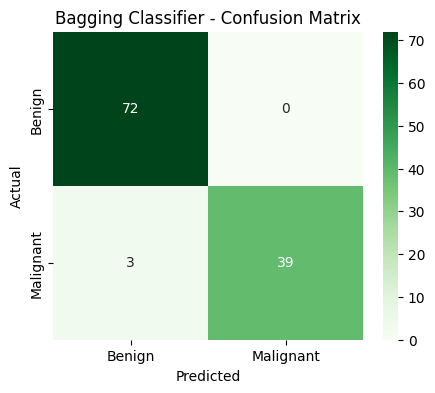

In [13]:
cm = confusion_matrix(y_test, y_pred_bagging)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bagging Classifier - Confusion Matrix")
plt.show()

## 11. Bootstrap Sampling

Bootstrap sampling is the process of randomly selecting samples from the original training dataset **with replacement**.

With replacement means:
- A data point can be selected more than once.
- Some data points may not be selected at all.
- Every bootstrap sample generally has the same number of rows as the original training dataset when max_samples=1.0.

### Example

Original dataset:

[10, 20, 30, 40, 50]

One possible bootstrap sample:

[10, 20, 20, 40, 50]

Notice:
- 20 appears twice.
- 30 is not selected.
- The sample still contains 5 observations.

Bagging trains each individual model using a different bootstrap sample.

In [14]:
# Create one bootstrap sample from training data

bootstrap_sample = X_train.sample(
    n=len(X_train),
    replace=True,
    random_state=42
)

print("Original training shape:", X_train.shape)
print("Bootstrap sample shape:", bootstrap_sample.shape)

bootstrap_sample.head()

Original training shape: (455, 30)
Bootstrap sample shape: (455, 30)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
417,15.50,21.08,102.9,803.1,0.11200,0.1571,0.1522,0.08481,0.2085,0.06864,...,23.17,27.65,157.1,1748.0,0.1517,0.4002,0.4211,0.2134,0.3003,0.10480
392,15.49,19.97,102.4,744.7,0.11600,0.1562,0.1891,0.09113,0.1929,0.06744,...,21.20,29.41,142.1,1359.0,0.1681,0.3913,0.5553,0.2121,0.3187,0.10190
77,18.05,16.15,120.2,1006.0,0.10650,0.2146,0.1684,0.10800,0.2152,0.06673,...,22.39,18.91,150.1,1610.0,0.1478,0.5634,0.3786,0.2102,0.3751,0.11080
441,17.27,25.42,112.4,928.8,0.08331,0.1109,0.1204,0.05736,0.1467,0.05407,...,20.38,35.46,132.8,1284.0,0.1436,0.4122,0.5036,0.1739,0.2500,0.07944
2,19.69,21.25,130.0,1203.0,0.10960,0.1599,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [15]:
# Check how many unique rows were selected
unique_rows = bootstrap_sample.drop_duplicates().shape[0]

# Calculate duplicate selections
duplicate_count = len(bootstrap_sample) - unique_rows

print("Total observations:", len(bootstrap_sample))
print("Unique observations:", unique_rows)
print("Repeated observations:", duplicate_count)
print("Observations not selected:", len(X_train) - unique_rows)

Total observations: 455
Unique observations: 275
Repeated observations: 180
Observations not selected: 180


In [16]:
# Get the bootstrap sample indices used by the first three trees

for i in range(3):
    sample_indices = bagging_model.estimators_samples_[i]

    print(f"\nTree {i+1}")
    print("Total sampled rows:", len(sample_indices))
    print("Unique sampled rows:", len(np.unique(sample_indices)))
    print("Repeated selections:", len(sample_indices) - len(np.unique(sample_indices)))


Tree 1
Total sampled rows: 455
Unique sampled rows: 281
Repeated selections: 174

Tree 2
Total sampled rows: 455
Unique sampled rows: 286
Repeated selections: 169

Tree 3
Total sampled rows: 455
Unique sampled rows: 279
Repeated selections: 176


## 12. Pasting

Pasting is an ensemble technique similar to Bagging.

The main difference is how training samples are selected.

- Bagging: Sampling is performed WITH replacement.
- Pasting: Sampling is performed WITHOUT replacement.

### How Pasting works

1. Randomly select a subset of observations from the training dataset.
2. Do not select the same observation more than once within a subset.
3. Train an individual model on each selected subset.
4. Repeat the process to train multiple models.
5. Combine their predictions using majority voting.

### Important

In Pasting, different models can still share some observations. However, an observation cannot appear more than once within the same model's training sample.

Pasting can introduce diversity between models by training them on different subsets.

In [17]:
# Create Pasting Classifier

pasting_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

# Train the model
pasting_model.fit(X_train, y_train)

# Predictions
y_pred_pasting = pasting_model.predict(X_test)

# Evaluate
print("Pasting Accuracy:", accuracy_score(y_test, y_pred_pasting))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_pasting,
    target_names=['Benign', 'Malignant']
))

Pasting Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [18]:
# Inspect the first three estimators

for i in range(3):
    sample_indices = pasting_model.estimators_samples_[i]

    print(f"\nTree {i+1}")
    print("Total sampled rows:", len(sample_indices))
    print("Unique sampled rows:", len(np.unique(sample_indices)))
    print("Repeated selections:", len(sample_indices) - len(np.unique(sample_indices)))


Tree 1
Total sampled rows: 364
Unique sampled rows: 364
Repeated selections: 0

Tree 2
Total sampled rows: 364
Unique sampled rows: 364
Repeated selections: 0

Tree 3
Total sampled rows: 364
Unique sampled rows: 364
Repeated selections: 0


In [19]:
comparison = pd.DataFrame({
    'Model': ['Bagging', 'Pasting'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bagging),
        accuracy_score(y_test, y_pred_pasting)
    ]
})

comparison

,Model,Accuracy
0,Bagging,0.973684
1,Pasting,0.973684


## 13. Random Subspaces

Random Subspaces is an ensemble technique in which each individual model is trained using a randomly selected subset of features (columns).

Unlike normal Bagging, where models can use all features, Random Subspaces gives each model access to only a portion of the available features.

### How it works

1. Start with the original training dataset.
2. Randomly select a subset of features.
3. Train a model using the selected features.
4. Repeat the process to create multiple models.
5. Combine their predictions using majority voting.

### Important Parameters

- max_features: Controls the fraction of features selected for each model.
- max_samples: Controls the fraction of training observations selected.
- bootstrap: Controls whether observations are sampled with replacement.
- bootstrap_features: Controls whether features are sampled with replacement.

### Example

Suppose our dataset contains 30 features.

If max_features=0.5, each model receives approximately 15 randomly selected features.

Each model may receive a different subset of features.

In [20]:
# Random Subspaces Classifier

random_subspaces_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    max_features=0.5,
    bootstrap=True,
    bootstrap_features=False,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_subspaces_model.fit(X_train, y_train)

# Predictions
y_pred_subspaces = random_subspaces_model.predict(X_test)

# Evaluation
print("Random Subspaces Accuracy:",
      accuracy_score(y_test, y_pred_subspaces))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_subspaces,
    target_names=['Benign', 'Malignant']
))

Random Subspaces Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [21]:
print("Total features in dataset:", X_train.shape[1])

for i in range(3):
    feature_indices = random_subspaces_model.estimators_features_[i]

    print(f"\nTree {i+1}")
    print("Number of selected features:", len(feature_indices))
    print("Selected feature indices:", feature_indices)

Total features in dataset: 30

Tree 1
Number of selected features: 15
Selected feature indices: [25 17 11 21  0  8 15  5 16 14 29 20  3 24  1]

Tree 2
Number of selected features: 15
Selected feature indices: [ 0  6  4 20 24 25 29 11  1  7  2 12 17 21 18]

Tree 3
Number of selected features: 15
Selected feature indices: [16 19 12  9 10  1 11  2 20 27  4 17 29 25 15]


In [22]:
comparison = pd.DataFrame({
    'Model': [
        'Bagging',
        'Pasting',
        'Random Subspaces'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bagging),
        accuracy_score(y_test, y_pred_pasting),
        accuracy_score(y_test, y_pred_subspaces)
    ]
})

comparison.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
0,Bagging,0.973684
1,Pasting,0.973684
2,Random Subspaces,0.973684


## 14. Random Patches

Random Patches is an ensemble technique in which every individual model is trained using:

1. A random subset of observations (rows).
2. A random subset of features (columns).

It combines the concepts of Pasting/Bagging and Random Subspaces.

### How it works

1. Randomly select a subset of rows.
2. Randomly select a subset of features.
3. Train a model using the selected rows and features.
4. Repeat the process to train multiple models.
5. Combine their predictions using majority voting.

### Example

Consider a dataset containing:

- 500 observations
- 30 features

If we set:

- max_samples = 0.8 → each model gets 80% of the rows.
- max_features = 0.5 → each model gets 50% of the features.

Each model learns from a different random patch of the original dataset.

### Difference from Random Subspaces

- Random Subspaces: Random subset of features.
- Random Patches: Random subset of both rows and features.

In [23]:
# Random Patches Classifier

random_patches_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=0.8,
    max_features=0.5,
    bootstrap=True,
    bootstrap_features=False,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_patches_model.fit(X_train, y_train)

# Predictions
y_pred_patches = random_patches_model.predict(X_test)

# Evaluation
print("Random Patches Accuracy:",
      accuracy_score(y_test, y_pred_patches))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_patches,
    target_names=['Benign', 'Malignant']
))

Random Patches Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [24]:
for i in range(3):
    sample_indices = random_patches_model.estimators_samples_[i]
    feature_indices = random_patches_model.estimators_features_[i]

    print(f"\nTree {i+1}")
    print("Selected rows:", len(sample_indices))
    print("Unique rows:", len(np.unique(sample_indices)))
    print("Selected features:", len(feature_indices))
    print("Feature indices:", feature_indices)


Tree 1
Selected rows: 364
Unique rows: 251
Selected features: 15
Feature indices: [25 17 11 21  0  8 15  5 16 14 29 20  3 24  1]

Tree 2
Selected rows: 364
Unique rows: 255
Selected features: 15
Feature indices: [ 0  6  4 20 24 25 29 11  1  7  2 12 17 21 18]

Tree 3
Selected rows: 364
Unique rows: 241
Selected features: 15
Feature indices: [16 19 12  9 10  1 11  2 20 27  4 17 29 25 15]


In [25]:
comparison = pd.DataFrame({
    'Model': [
        'Bagging',
        'Pasting',
        'Random Subspaces',
        'Random Patches'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bagging),
        accuracy_score(y_test, y_pred_pasting),
        accuracy_score(y_test, y_pred_subspaces),
        accuracy_score(y_test, y_pred_patches)
    ]
})

comparison = comparison.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

comparison

,Model,Accuracy
0,Bagging,0.973684
1,Pasting,0.973684
2,Random Subspaces,0.973684
3,Random Patches,0.973684


## Bagging Regressor

Bagging Regressor is an ensemble learning technique used for **regression problems**, where the goal is to predict continuous numerical values.

It works on the principle of Bootstrap Aggregating (Bagging).

Instead of training a single regression model, Bagging Regressor trains multiple models using different bootstrap samples of the training dataset.

### How Bagging Regressor Works

1. Create multiple bootstrap samples from the original training dataset.
2. Train an individual regression model on each bootstrap sample.
3. Each model makes its own numerical prediction.
4. Combine all predictions by calculating their average.
5. Return the average as the final prediction.

### Example

Suppose we want to predict the price of a house.

Five regression models predict:

- Model 1: ₹40 Lakhs
- Model 2: ₹42 Lakhs
- Model 3: ₹45 Lakhs
- Model 4: ₹41 Lakhs
- Model 5: ₹43 Lakhs

The final prediction is the average:

Final Prediction = (40 + 42 + 45 + 41 + 43) / 5

Final Prediction = ₹42.2 Lakhs

### Important Parameters

- **estimator:** The base regression algorithm used by the ensemble.
- **n_estimators:** Number of individual regression models.
- **max_samples:** Number or fraction of training observations selected for each model.
- **max_features:** Number or fraction of features selected for each model.
- **bootstrap:** Whether rows are sampled with replacement.
- **bootstrap_features:** Whether features are sampled with replacement.
- **random_state:** Ensures reproducibility.
- **n_jobs:** Controls parallel processing.

### Evaluation Metrics

Since Bagging Regressor predicts continuous values, we use regression evaluation metrics:

1. **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted values.
2. **MSE (Mean Squared Error):** Average squared prediction error.
3. **RMSE (Root Mean Squared Error):** Square root of MSE, expressed in the target variable's units.
4. **R² Score:** Measures how much variation in the target variable is explained by the model.

### Advantages

- Reduces model variance.
- Helps reduce overfitting, especially with unstable base estimators such as Decision Trees.
- Improves prediction stability.
- Can be used with different regression algorithms.

### Limitations

- Requires more computational resources than a single model.
- Model interpretation becomes more difficult.
- Does not necessarily improve performance for every dataset.
- May not significantly reduce bias.

### When to Use Bagging Regressor

- When a regression model has high variance.
- When a Decision Tree Regressor overfits.
- When you want more stable predictions.
- When you have sufficient computational resources.

### Bagging Classifier vs Bagging Regressor

| Bagging Classifier | Bagging Regressor |
|---|---|
| Used for classification | Used for regression |
| Predicts class labels | Predicts continuous values |
| Combines predictions using majority voting | Combines predictions using averaging |
| Accuracy, Precision, Recall, F1 | MAE, MSE, RMSE, R² |